# Identificação de áreas alagadas em imagens de Louisiana

**Integrantes:** PREENCHER os nomes completos.

**Dataset:** [Louisiana flood 2016 — Rahul T P, Kaggle](https://www.kaggle.com/datasets/rahultp97/louisiana-flood-2016), versão 4, licença indicada como CC0: Public Domain.

**Apresentação:** PENDENTE — inserir o link dos slides.

**Vídeo:** PENDENTE — inserir o link do vídeo de até 10 minutos, com todos os integrantes apresentando.

Os links devem permitir acesso ao professor. Fonte consultada em 05/11/2026.

## 1. Problema e contexto

O objetivo é **classificar imagens como alagadas (1) ou não alagadas (0)**. Utilizamos imagens das enchentes de agosto de 2016 em Louisiana, publicadas por Rahul T P no Kaggle. O autor referencia a [NOAA](https://geodesy.noaa.gov/storm_archive/storms/aug2016_lafloods/index.html) e o [LouisianaView](http://louisianaview.org/2016/08/historic-louisiana-floods-august-2016/) como fontes.

Extraímos medidas de cor e textura dos pixels, organizamos essas medidas em uma tabela com Pandas e treinamos um **Random Forest**. A classificação identifica alagamento em imagens já capturadas; não prevê enchentes futuras. O dataset contém pares de imagens antes/depois e durante o evento, que exigem cuidado na separação entre treino e teste.

In [1]:
# Execute as células em ordem no Jupyter ou Google Colab.
# Se necessário, descomente a linha abaixo para instalar as bibliotecas.
# %pip install pandas numpy pillow matplotlib seaborn scikit-learn

from pathlib import Path
import io
import hashlib
import zipfile
import urllib.request
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

%matplotlib inline
sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 15)

## 2. Download do dataset

A célula abaixo baixa a versão 4 do dataset, aproximadamente **96 MB**, pelo endereço público do Kaggle. O ZIP é lido diretamente e reutilizado nas próximas execuções. Para executar novamente, é necessário internet ou o ZIP ao lado do notebook. A entrega continua sendo apenas este arquivo `.ipynb`, com código, explicações e resultados salvos.

In [2]:
DOWNLOAD_URL = "https://www.kaggle.com/api/v1/datasets/download/rahultp97/louisiana-flood-2016?datasetVersionNumber=4"
arquivo_zip = Path("louisiana-flood-2016-v4.zip")

if not arquivo_zip.exists():
    temporario = arquivo_zip.with_suffix(".download")
    try:
        urllib.request.urlretrieve(DOWNLOAD_URL, temporario)
        if not zipfile.is_zipfile(temporario):
            raise ValueError("Download inválido. Baixe a versão 4 na página do dataset.")
        temporario.replace(arquivo_zip)
    finally:
        if temporario.exists():
            temporario.unlink()

with zipfile.ZipFile(arquivo_zip) as z:
    assert z.testzip() is None, "Há um arquivo corrompido no ZIP."
    print("Arquivos no dataset:", len(z.namelist()))
print("Tamanho do ZIP:", round(arquivo_zip.stat().st_size / 1_000_000, 2), "MB")

Arquivos no dataset: 324
Tamanho do ZIP: 96.06 MB


## 3. Importação, exploração e tipos de variáveis

Os CSVs são lidos com Pandas. Cada linha corresponde a uma imagem.

| Variável | Significado | Tipo e uso |
|---|---|---|
| `Image ID` | Nome do arquivo | Categórica nominal; identificador excluído do modelo |
| `Normal` | 1: antes/depois do evento; 0: durante o evento | Categórica binária; usada apenas na exploração |
| `Flooded` | 1: alagada; 0: não alagada | Categórica binária; variável-alvo |
| `particao` | Treino ou teste, segundo o dataset | Categórica nominal; organiza a divisão |
| `cena` | Nome-base que reúne imagens pareadas | Categórica nominal; verifica a separação dos pares |
| `largura`, `altura` | Dimensões em pixels | Numéricas discretas; verificam as imagens |
| Atributos visuais | Medidas calculadas dos pixels | Numéricas contínuas; entradas do modelo |

`particao` e `cena` são colunas criadas para organizar a análise. **`Normal=0` não significa necessariamente alagamento.** O nome do arquivo pode revelar o alvo pelos sufixos `_0` e `_1`; por isso não entra no modelo.

In [3]:
partes = []
with zipfile.ZipFile(arquivo_zip) as z:
    for particao in ["train", "test"]:
        tabela = pd.read_csv(z.open(f"{particao}.csv"))
        tabela["particao"] = particao
        partes.append(tabela)
dados_originais = pd.concat(partes, ignore_index=True)
dados = dados_originais.copy(deep=True)
# O nome-base reúne a imagem de referência e sua imagem correspondente durante a enchente.
dados["cena"] = dados["Image ID"].str.replace(r"(_[01])?\.png$", "", regex=True)
print(f"Linhas: {len(dados)} | Colunas originais: 3 | Cenas: {dados['cena'].nunique()}")
display(dados.head(8))
dados.info()
print("Valores únicos por coluna:")
display(dados.nunique().rename("quantidade").to_frame())
print("Distribuições dos códigos (médias dos rótulos não são medidas de severidade):")
display(dados[["Normal", "Flooded"]].describe())
display(pd.crosstab(dados["particao"], dados["Flooded"], margins=True))
print("Relação entre fase do evento e alagamento:")
display(pd.crosstab(dados["Normal"], dados["Flooded"]))

Linhas: 322 | Colunas originais: 3 | Cenas: 161


,Image ID,Normal,Flooded,particao,cena
0,2004_0.png,0,0,train,2004
1,2008_0.png,0,0,train,2008
2,11006.png,1,0,train,11006
3,10005_0.png,0,0,train,10005
4,15003_0.png,0,0,train,15003
5,13001_1.png,0,1,train,13001
6,10008_1.png,0,1,train,10008
7,1010_1.png,0,1,train,1010


<class 'pandas.DataFrame'>
RangeIndex: 322 entries, 0 to 321
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Image ID  322 non-null    str  
 1   Normal    322 non-null    int64
 2   Flooded   322 non-null    int64
 3   particao  322 non-null    str  
 4   cena      322 non-null    str  
dtypes: int64(2), str(3)
memory usage: 12.7 KB
Valores únicos por coluna:


,quantidade
Image ID,322
Normal,2
Flooded,2
particao,2
cena,161


Distribuições dos códigos (médias dos rótulos não são medidas de severidade):


,Normal,Flooded
count,322.000000,322.000000
mean,0.500000,0.316770
std,0.500778,0.465941
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.500000,0.000000
75%,1.000000,1.000000
max,1.000000,1.000000


Flooded,0,1,All
particao,,,
test,36,16,52
train,184,86,270
All,220,102,322


Relação entre fase do evento e alagamento:


Flooded,0,1
Normal,,
0,59,102
1,161,0


## 4. Verificação e tratamento da qualidade

Verificamos valores faltantes, linhas duplicadas, códigos diferentes de 0/1 e imagens ausentes ou ilegíveis. Preservamos os dados originais e interrompemos a execução caso uma imagem ou rótulo esteja inválido.

Também comparamos o conteúdo dos arquivos com SHA-256 para detectar imagens idênticas com nomes diferentes. **Essa verificação é necessária porque encontramos cópias entre treino e teste.** A correção remove do treino a cena repetida, mantendo o teste reservado.

In [4]:
print("Ausências nos CSVs:")
display(dados.isna().sum().rename("faltantes").to_frame())
duplicadas = int(dados.duplicated().sum())
print("Linhas integralmente duplicadas:", duplicadas)
assert dados.notna().all().all(), "Investigar registros sem informação antes de modelar."
assert dados["Image ID"].is_unique, "Investigar nomes de imagens repetidos."
for coluna in ["Normal", "Flooded"]:
    assert dados[coluna].isin([0, 1]).all(), f"Código inválido em {coluna}."
dados = dados.drop_duplicates().copy()

inventario, problemas = [], []
with zipfile.ZipFile(arquivo_zip) as z:
    nomes = set(z.namelist())
    for _, linha in dados.iterrows():
        caminho = f"{linha['particao']}/{linha['Image ID']}"
        try:
            if caminho not in nomes:
                raise FileNotFoundError(caminho)
            conteudo = z.read(caminho)
            with Image.open(io.BytesIO(conteudo)) as im:
                im.load()
                assert im.width > 0 and im.height > 0
                inventario.append({"Image ID": linha["Image ID"], "largura": im.width,
                                   "altura": im.height, "modo": im.mode,
                                   "sha_imagem": hashlib.sha256(conteudo).hexdigest()})
        except Exception as erro:
            problemas.append({"arquivo": caminho, "erro": str(erro)})
print("Imagens com problema:", len(problemas))
assert not problemas, problemas
dados = dados.merge(pd.DataFrame(inventario), on="Image ID", validate="one_to_one")
print("Imagens com conteúdo binário repetido:", int(dados["sha_imagem"].duplicated().sum()))
display(dados.groupby(["largura", "altura", "modo"]).size().rename("imagens").to_frame())
display(dados[["largura", "altura"]].describe())

# Preservamos o teste original e excluímos do treino a cena que repete seu conteúdo.
# A decisão é baseada na identidade dos arquivos, sem consultar desempenho do modelo.
hashes_reservados = set(dados.loc[dados["particao"].eq("test"), "sha_imagem"])
repetidas_no_treino = dados["particao"].eq("train") & dados["sha_imagem"].isin(hashes_reservados)
cenas_excluir_treino = set(dados.loc[repetidas_no_treino, "cena"])
remover = dados["particao"].eq("train") & dados["cena"].isin(cenas_excluir_treino)
print("Registros removidos do treino por repetição do teste:")
display(dados.loc[remover, ["Image ID", "cena", "particao", "Flooded"]])
dados = dados.loc[~remover].reset_index(drop=True)
print("Base após a correção:", len(dados), "imagens.")
print("Nenhuma imputação foi necessária; duas imagens repetidas foram retiradas do treino.")

Ausências nos CSVs:


,faltantes
Image ID,0
Normal,0
Flooded,0
particao,0
cena,0


Linhas integralmente duplicadas: 0


Imagens com problema: 0
Imagens com conteúdo binário repetido: 2


,,,imagens
largura,altura,modo,
512,360,RGB,322


,largura,altura
count,322.0,322.0
mean,512.0,360.0
std,0.0,0.0
min,512.0,360.0
25%,512.0,360.0
50%,512.0,360.0
75%,512.0,360.0
max,512.0,360.0


Registros removidos do treino por repetição do teste:


,Image ID,cena,particao,Flooded
178,2010.png,2010,train,0
219,2010_0.png,2010,train,0


Base após a correção: 320 imagens.
Nenhuma imputação foi necessária; duas imagens repetidas foram retiradas do treino.


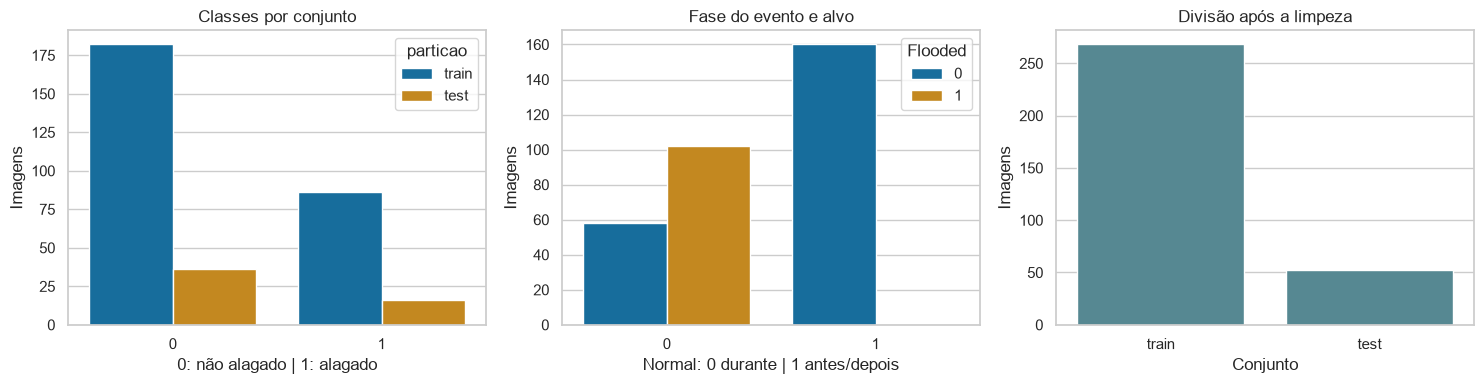

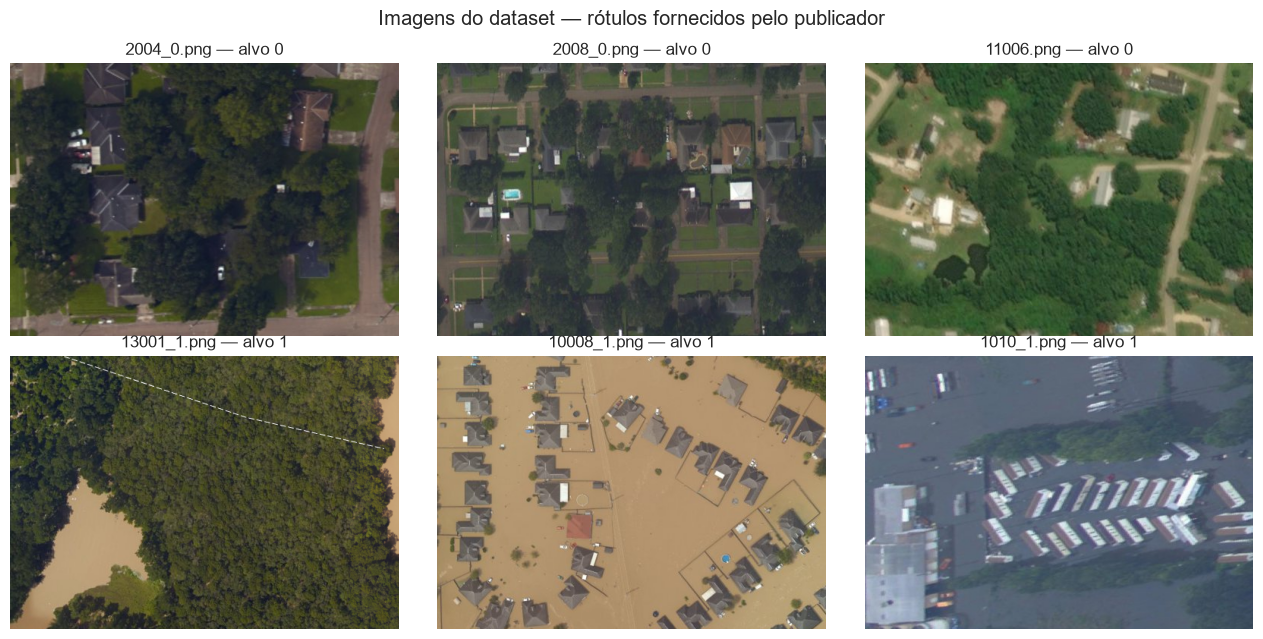

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=dados, x="Flooded", hue="particao", ax=axes[0])
axes[0].set(title="Classes por conjunto", xlabel="0: não alagado | 1: alagado", ylabel="Imagens")
sns.countplot(data=dados, x="Normal", hue="Flooded", ax=axes[1])
axes[1].set(title="Fase do evento e alvo", xlabel="Normal: 0 durante | 1 antes/depois", ylabel="Imagens")
sns.countplot(data=dados, x="particao", ax=axes[2], color="#4c8f9c")
axes[2].set(title="Divisão após a limpeza", xlabel="Conjunto", ylabel="Imagens")
plt.tight_layout()
plt.show()

# Exemplos ilustrativos; os nomes servem apenas para rastrear a origem da figura.
amostras = pd.concat([dados.query("Flooded == 0").head(3), dados.query("Flooded == 1").head(3)])
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
with zipfile.ZipFile(arquivo_zip) as z:
    for ax, (_, linha) in zip(axes.flat, amostras.iterrows()):
        im = Image.open(io.BytesIO(z.read(f"{linha['particao']}/{linha['Image ID']}"))).convert("RGB")
        ax.imshow(im)
        ax.set_title(f"{linha['Image ID']} — alvo {linha['Flooded']}")
        ax.axis("off")
fig.suptitle("Imagens do dataset — rótulos fornecidos pelo publicador")
plt.tight_layout()
plt.show()

### Resultado da verificação

O pacote tem **322 imagens**: 270 de treino e 52 de teste. Não há valores faltantes, portanto **não foi necessário imputar dados**. As imagens puderam ser lidas.

Encontramos duas cópias: `train/2010.png` repete `test/2009.png`, e `train/2010_0.png` repete `test/2009_0.png`. Retiramos o par do treino. A base corrigida tem **320 imagens: 268 de treino e 52 de teste**, com **218 não alagadas** e **102 alagadas**.

Todas as imagens antes/depois estão rotuladas como não alagadas; durante o evento há as duas classes. Excluímos `Normal` para evitar esse atalho na classificação. O desbalanceamento também exige avaliar precisão, recall e F1, além da acurácia.

## 5. Extração e seleção dos atributos

Para usar Random Forest, transformamos as imagens em uma tabela de **45 atributos numéricos**. Cada imagem é convertida para RGB, redimensionada para **128 × 128 pixels**, e suas intensidades são divididas por 255 para ficar entre 0 e 1.

| Grupo | Atributos extraídos | Quantidade |
|---|---|---|
| RGB: vermelho, verde e azul | Média, desvio-padrão e percentis 10 e 90 por canal | 12 |
| HSV: matiz, saturação e brilho | Média e desvio-padrão por canal | 6 |
| Histogramas RGB | Frequências em 8 faixas de intensidade por canal | 24 |
| Textura em cinza | Contraste, diferenças entre pixels vizinhos e entropia | 3 |

Essas medidas descrevem cor, variação e textura, características potencialmente relacionadas à presença de água. São calculadas separadamente para cada imagem, sem usar o rótulo. Excluímos identificadores, nomes, fase do evento e dimensões da entrada do modelo. A seleção é inicial e baseada no problema, sem escolher atributos a partir do resultado do teste.

In [6]:
def extrair_atributos(conteudo):
    with Image.open(io.BytesIO(conteudo)) as im:
        rgb_im = im.convert("RGB").resize((128, 128), Image.Resampling.BILINEAR)
        rgb = np.asarray(rgb_im, dtype=np.float64) / 255.0
        hsv = np.asarray(rgb_im.convert("HSV"), dtype=np.float64) / 255.0
        cinza = np.asarray(rgb_im.convert("L"), dtype=np.float64) / 255.0
    atributos = {}
    for indice, canal in enumerate(["r", "g", "b"]):
        valores = rgb[:, :, indice]
        atributos[f"{canal}_media"] = valores.mean()
        atributos[f"{canal}_desvio"] = valores.std()
        atributos[f"{canal}_p10"] = np.quantile(valores, 0.10)
        atributos[f"{canal}_p90"] = np.quantile(valores, 0.90)
        frequencias, _ = np.histogram(valores, bins=8, range=(0, 1))
        for faixa, frequencia in enumerate(frequencias / valores.size):
            atributos[f"{canal}_hist_{faixa}"] = frequencia
    for indice, canal in enumerate(["h", "s", "v"]):
        atributos[f"{canal}_media"] = hsv[:, :, indice].mean()
        atributos[f"{canal}_desvio"] = hsv[:, :, indice].std()
    atributos["cinza_contraste"] = cinza.std()
    atributos["cinza_bordas"] = (np.abs(np.diff(cinza, axis=0)).mean() +
                                  np.abs(np.diff(cinza, axis=1)).mean()) / 2
    hist, _ = np.histogram(cinza, bins=256, range=(0, 1))
    p = hist[hist > 0] / cinza.size
    atributos["cinza_entropia"] = -(p * np.log2(p)).sum() / 8
    return atributos

linhas = []
with zipfile.ZipFile(arquivo_zip) as z:
    for _, linha in dados.iterrows():
        atributos = extrair_atributos(z.read(f"{linha['particao']}/{linha['Image ID']}"))
        linhas.append(atributos)
atributos = pd.DataFrame(linhas, index=dados.index)
print("Tabela de atributos:", atributos.shape)
display(atributos.head())
display(atributos.describe().T.round(4))
print("Valores faltantes:", int(atributos.isna().sum().sum()))
print("Valores infinitos:", int(np.isinf(atributos.to_numpy()).sum()))
assert atributos.shape == (len(dados), 45)
assert np.isfinite(atributos.to_numpy()).all()
# Estatísticas definidas em [0,1], com tolerância para arredondamento numérico.
assert (atributos.to_numpy() >= -1e-12).all() and (atributos.to_numpy() <= 1 + 1e-12).all()

Tabela de atributos: (320, 45)


,r_media,r_desvio,r_p10,r_p90,r_hist_0,r_hist_1,r_hist_2,...,s_media,s_desvio,v_media,v_desvio,cinza_contraste,cinza_bordas,cinza_entropia
0,0.232437,0.124493,0.113725,0.450980,0.154297,0.518066,0.174255,...,0.256800,0.136106,0.257687,0.111030,0.101560,0.018882,0.793193
1,0.274990,0.092729,0.176471,0.388235,0.000000,0.452209,0.417175,...,0.166224,0.082890,0.299677,0.084344,0.082123,0.018946,0.754904
2,0.312536,0.158800,0.164706,0.556863,0.001587,0.505737,0.182617,...,0.366032,0.075441,0.381353,0.122503,0.126074,0.025275,0.821995
3,0.407005,0.130487,0.262745,0.596078,0.000000,0.065063,0.413879,...,0.277293,0.151986,0.437522,0.122065,0.120228,0.032321,0.845391
4,0.430190,0.148275,0.286275,0.694118,0.000000,0.025818,0.457703,...,0.216149,0.082828,0.434635,0.145769,0.128277,0.036427,0.827844


,count,mean,std,min,25%,50%,75%,max
r_media,320.0,0.3479,0.0947,0.1490,0.2773,0.3352,0.4024,0.6991
r_desvio,320.0,0.1387,0.0414,0.0153,0.1139,0.1426,0.1647,0.2435
r_p10,320.0,0.1830,0.0667,0.0235,0.1412,0.1725,0.2196,0.4824
r_p90,320.0,0.5276,0.1311,0.1882,0.4353,0.5353,0.6196,0.8745
r_hist_0,320.0,0.0434,0.0726,0.0000,0.0000,0.0089,0.0564,0.4686
r_hist_1,320.0,0.3029,0.2019,0.0004,0.1512,0.2864,0.4250,0.9643
r_hist_2,320.0,0.2808,0.1326,0.0016,0.1937,0.2611,0.3469,0.7657
r_hist_3,320.0,0.1780,0.1080,0.0000,0.1010,0.1713,0.2397,0.7073
r_hist_4,320.0,0.1093,0.1120,0.0000,0.0315,0.0801,0.1495,0.6183
r_hist_5,320.0,0.0665,0.1102,0.0000,0.0069,0.0266,0.0745,0.6859


Valores faltantes: 0
Valores infinitos: 0


## 6. Visualização dos atributos

Usamos somente o **treino** nesta exploração. Os histogramas mostram distribuições; os boxplots comparam mediana e dispersão por classe; a dispersão mostra a relação entre azul médio e saturação. Sobreposição entre classes indica que um atributo isolado pode não separar bem as imagens.

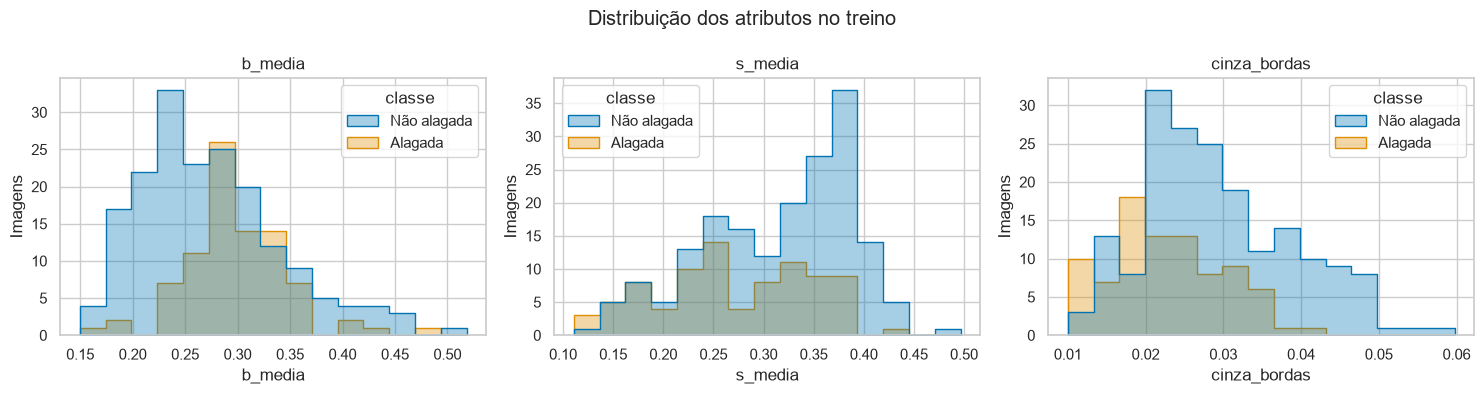

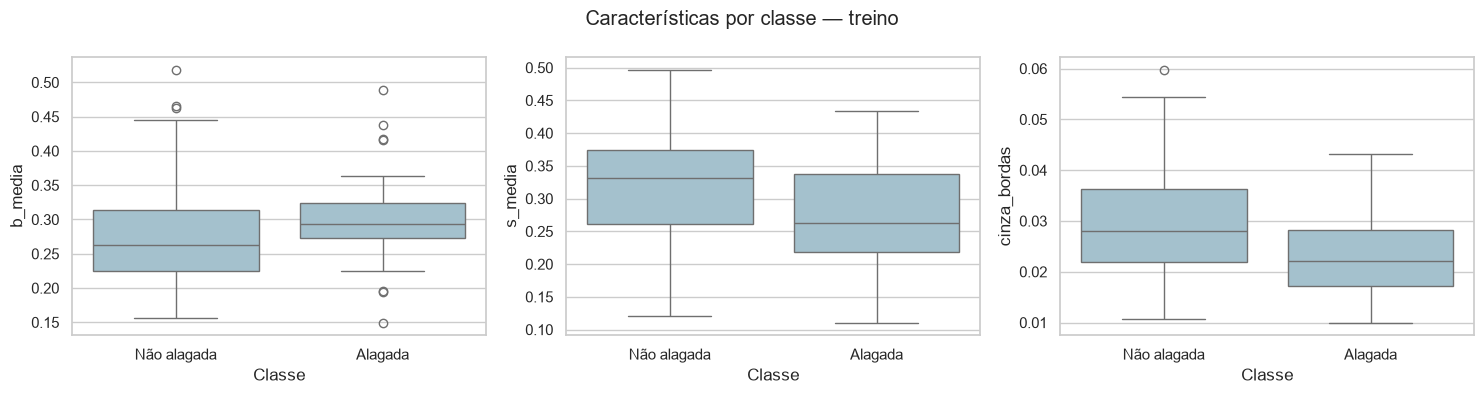

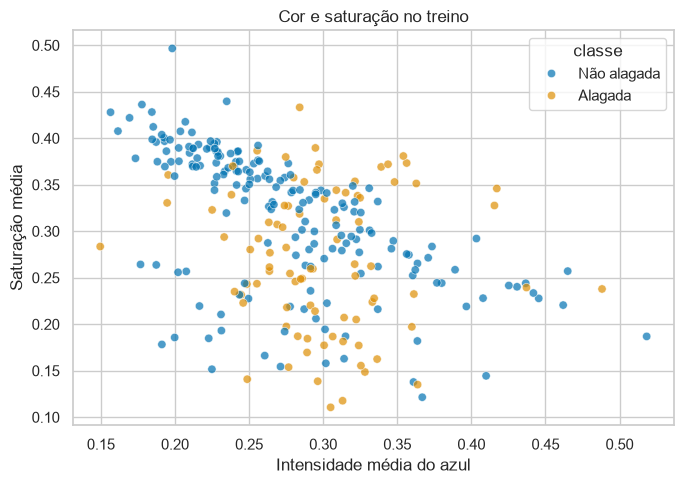

In [7]:
mascara_treino = dados["particao"].eq("train")
exploracao = atributos.loc[mascara_treino].copy()
exploracao["classe"] = dados.loc[mascara_treino, "Flooded"].map({0: "Não alagada", 1: "Alagada"})
selecionadas_graficos = ["b_media", "s_media", "cinza_bordas"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, coluna in zip(axes, selecionadas_graficos):
    sns.histplot(data=exploracao, x=coluna, hue="classe", bins=15, ax=ax, element="step", alpha=0.35)
    ax.set(title=coluna, ylabel="Imagens")
fig.suptitle("Distribuição dos atributos no treino")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, coluna in zip(axes, selecionadas_graficos):
    sns.boxplot(data=exploracao, x="classe", y=coluna, ax=ax, color="#9dc4d4")
    ax.set(xlabel="Classe", ylabel=coluna)
fig.suptitle("Características por classe — treino")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=exploracao, x="b_media", y="s_media", hue="classe", alpha=0.7, ax=ax)
ax.set(title="Cor e saturação no treino", xlabel="Intensidade média do azul", ylabel="Saturação média")
plt.tight_layout()
plt.show()

## 7. Separação de X/y, treino/teste e padronização

**`X` contém os 45 atributos visuais; `y` contém `Flooded`.** Mantemos a divisão do publicador, após retirar do treino as cópias do teste. Conferimos que cenas pareadas e arquivos idênticos não atravessam a divisão.

Os pixels já foram normalizados para [0,1]. Aplicamos também **StandardScaler**, ajustado somente no treino, para atender à padronização pedida no enunciado. Random Forest normalmente não depende dela. Não há preditores categóricos que necessitem de one-hot: os identificadores foram excluídos e o alvo já usa códigos 0/1.

In [8]:
mascara_teste = dados["particao"].eq("test")
cenas_treino = set(dados.loc[mascara_treino, "cena"])
cenas_teste = set(dados.loc[mascara_teste, "cena"])
hashes_treino = set(dados.loc[mascara_treino, "sha_imagem"])
hashes_teste = set(dados.loc[mascara_teste, "sha_imagem"])
assert cenas_treino.isdisjoint(cenas_teste), "Cenas pareadas atravessam a divisão."
assert hashes_treino.isdisjoint(hashes_teste), "Imagens idênticas atravessam a divisão."

X = atributos.copy()
y = dados["Flooded"].astype(int).copy()
X_train, X_test = X.loc[mascara_treino], X.loc[mascara_teste]
y_train, y_test = y.loc[mascara_treino], y.loc[mascara_teste]
print("X:", X.shape, "| y:", y.shape)
print("Treino:", X_train.shape, "| teste:", X_test.shape)
print("Cenas de treino:", len(cenas_treino), "| cenas de teste:", len(cenas_teste))
print("Cenas compartilhadas:", len(cenas_treino & cenas_teste))
print("Conteúdos binários compartilhados:", len(hashes_treino & hashes_teste))

X: (320, 45) | y: (320,)
Treino: (268, 45) | teste: (52, 45)
Cenas de treino: 134 | cenas de teste: 26
Cenas compartilhadas: 0
Conteúdos binários compartilhados: 0


## 8. Treinamento do modelo

Treinamos um **RandomForestClassifier** com **200 árvores**, profundidade máxima **10** e semente **42**. O modelo é adequado à classificação supervisionada com atributos numéricos e permite representar relações não lineares.

A Pipeline ajusta o StandardScaler e o classificador apenas com o treino. Os parâmetros são fixos; não foram escolhidos pelo desempenho no teste.

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

modelo = Pipeline([
    ("padronizacao", StandardScaler()),
    ("classificador", RandomForestClassifier(
        n_estimators=200, max_depth=10, random_state=42)),
])
modelo.fit(X_train, y_train)
print("Random Forest treinado com", len(X_train), "imagens.")

Random Forest treinado com 268 imagens.


## 9. Avaliação no conjunto de teste

- **Acurácia:** proporção total de acertos.
- **Precisão de alagamento:** entre as imagens previstas como alagadas, quantas estão corretas.
- **Recall de alagamento:** quantas imagens alagadas foram identificadas.
- **F1:** combina precisão e recall. O F1 macro dá o mesmo peso às duas classes.
- **Matriz de confusão:** mostra os acertos e erros de cada classe.

O teste reservado é usado nesta etapa para avaliar o modelo treinado.

,Resultado
Acurácia,0.7885
Precisão — alagada,0.7778
Recall — alagada,0.4375
F1 — alagada,0.5600
F1 macro,0.7104


              precision    recall  f1-score   support

 Não alagada       0.79      0.94      0.86        36
     Alagada       0.78      0.44      0.56        16

    accuracy                           0.79        52
   macro avg       0.78      0.69      0.71        52
weighted avg       0.79      0.79      0.77        52



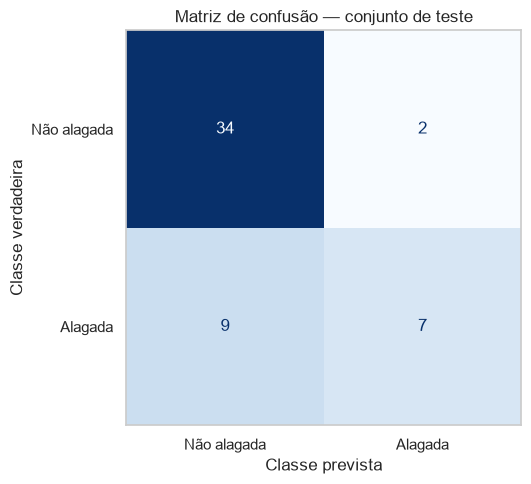

Acertos: 41 de 52 (78.8%)
Falsos positivos: 2 | Falsos negativos: 9
Imagens alagadas identificadas: 7 de 16


In [10]:
predicoes = modelo.predict(X_test)

metricas = pd.Series({
    "Acurácia": accuracy_score(y_test, predicoes),
    "Precisão — alagada": precision_score(y_test, predicoes, zero_division=0),
    "Recall — alagada": recall_score(y_test, predicoes, zero_division=0),
    "F1 — alagada": f1_score(y_test, predicoes, zero_division=0),
    "F1 macro": f1_score(y_test, predicoes, average="macro", zero_division=0),
})
display(metricas.round(4).rename("Resultado").to_frame())
print(classification_report(y_test, predicoes, labels=[0, 1],
      target_names=["Não alagada", "Alagada"], zero_division=0))

fig, ax = plt.subplots(figsize=(6.5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, predicoes, labels=[0, 1], display_labels=["Não alagada", "Alagada"],
    ax=ax, cmap="Blues", colorbar=False)
ax.set(title="Matriz de confusão — conjunto de teste",
       xlabel="Classe prevista", ylabel="Classe verdadeira")
ax.grid(False)
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, predicoes, labels=[0, 1]).ravel()
print(f"Acertos: {tn + tp} de {len(y_test)} ({accuracy_score(y_test, predicoes):.1%})")
print(f"Falsos positivos: {fp} | Falsos negativos: {fn}")
print(f"Imagens alagadas identificadas: {tp} de {tp + fn}")

## 10. Conclusão e reflexão crítica

O Random Forest acertou **41 das 52 imagens de teste (78,8%)**, com **F1 macro de 0,710**. Entretanto, identificou apenas **7 das 16 imagens alagadas (recall de 43,75%)**. Houve **9 falsos negativos** e **2 falsos positivos**. Assim, a acurácia isolada esconde uma dificuldade importante: mais da metade dos alagamentos do teste não foi reconhecida.

O experimento demonstra o fluxo de preparação, treinamento e avaliação, mas o desempenho ainda é insuficiente para decisões de resgate. A base é pequena, desbalanceada e representa um único evento. Cor e textura também podem confundir água com sombras ou outros elementos; os histogramas perdem informação de posição e forma. A média de matiz é uma aproximação, pois essa grandeza é circular.

A remoção de cópias e a separação por cena evitam os vazamentos identificados, mas não garantem independência geográfica completa, pois faltam coordenadas para verificar recortes próximos. Para melhorar o estudo, seria necessário validar em mais cenas e outros eventos, preservando um teste independente.

## Créditos

Grande parte deste trabalho foi inspirada nas atividades e nos trabalhos propostos pelo professor Flávio na disciplina de Inteligência Artificial e Aprendizado de Máquina, cursada no primeiro semestre de 2026.
